<center>

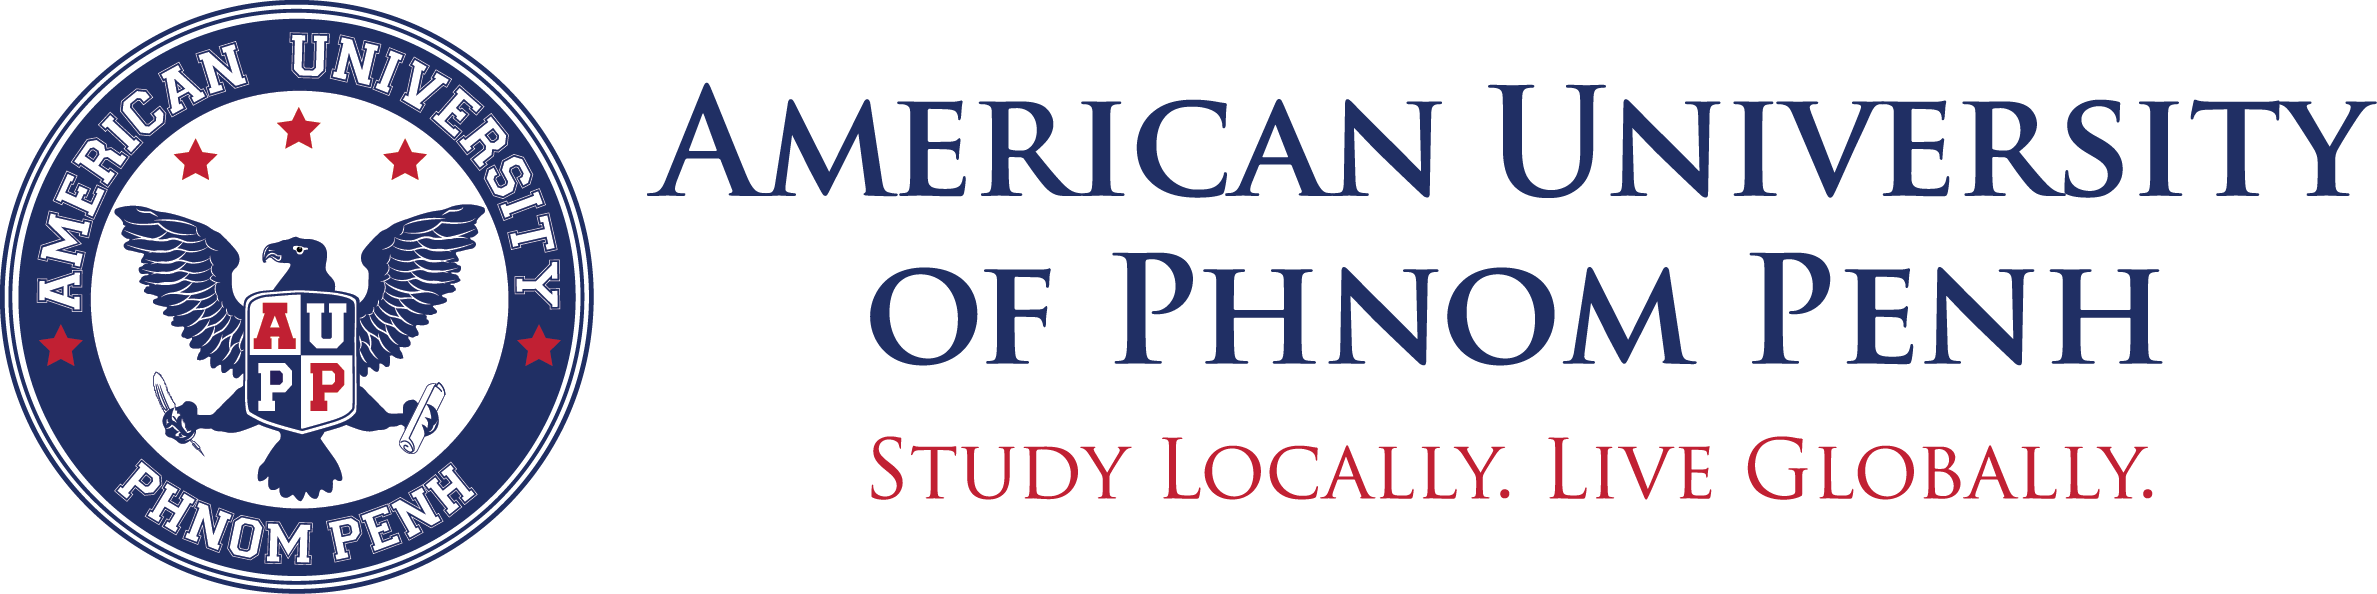

### School of Digital Technologies  
#### ITM-360: Artificial Intelligence
#### Lab-Practice: Multilayer Perceptrons
 
**Lecturer:** Kuntha Pin (Ph.D Eng.)

</center>

---

### Contents
### 1. Introduction
### 2. Implementation of Multilayer Perceptrons
---

# 1. Introduction

### Multilayer Perceptrons (MPLs) is a fundamental type of feedforward artificial neural network consisting of at least three layers of neurons: an input layer, one or more hidden layers, and an output layer.   
### We need MLPs because simple, single-layer models (like basic perceptrons or linear regression) cannot handle complex, real-world data, whereas MLPs can learn and represent almost any continuous function.  
### It is not much more complex to implement than simple linear models. The key conceptual difference is that we now concatenate multiple layers. 
  

# 2. Implementation of Multilayer Perceptrons

- Import the necessary libraries

In [1]:
import numpy as np
import struct

- Load Fashion-MNIST (IDX Files)

In [2]:
def load_images(path):
    with open(path, 'rb') as f:
        magic, num, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
        images = images.reshape(num, 28, 28)
    return images

def load_labels(path):
    with open(path, 'rb') as f:
        magic, num = struct.unpack(">II", f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
    return labels


# Load dataset, normalize the data, and flatten the images
X_train = load_images("train-images-idx3-ubyte") / 255.0
y_train = load_labels("train-labels-idx1-ubyte")

X_test  = load_images("t10k-images-idx3-ubyte") / 255.0
y_test  = load_labels("t10k-labels-idx1-ubyte")

=> This allows you to use downloaded files without TensorFlow or Keras.

## Activation & Loss Functions
- relu: Rectified Linear Unit, sets negative values to 0. Non-linear activation.  
- softmax: Converts logits to probabilities. Subtracting np.max prevents overflow.  
- cross_entropy: Measures difference between predicted probabilities and true labels.  
=> Together, these implement the forward pass for classification.

In [4]:
def relu(X):
    return np.maximum(0, X)

def softmax(X):
    exp = np.exp(X - np.max(X, axis=1, keepdims=True))
    return exp / exp.sum(axis=1, keepdims=True)

def cross_entropy(preds, labels):
    return -np.log(preds[np.arange(len(labels)), labels]).mean()

## Forward & Backward Functions

### Forward Function 
- Flattens each 28x28 image → 784 vector.  
- Layer 1: Linear transformation + ReLU.  
- Layer 2: Linear transformation → logits.  
- cache stores intermediate results for backpropagation.

In [ ]:
def forward(X, W1, b1, W2, b2):
    X = X.reshape(X.shape[0], -1)
    H_linear = X.dot(W1) + b1
    H = relu(H_linear)
    logits = H.dot(W2) + b2
    cache = (X, H, H_linear)
    return logits, cache


### Backward Function 
- Computes gradients of loss w.r.t parameters using chain rule.   
- Backpropagates through ReLU: gradient = 0 for negative activations.    
- Updates weights using SGD. 

In [6]:
def backward(cache, grad_out, W1, b1, W2, b2, lr):
    X, H, H_linear = cache
    batch_size = X.shape[0]
    dW2 = H.T.dot(grad_out)
    db2 = grad_out.sum(axis=0)
    dH = grad_out.dot(W2.T)
    dH_linear = dH * (H_linear > 0)
    dW1 = X.T.dot(dH_linear)
    db1 = dH_linear.sum(axis=0)
    W2 -= lr * dW2 / batch_size
    b2 -= lr * db2 / batch_size
    W1 -= lr * dW1 / batch_size
    b1 -= lr * db1 / batch_size
    return W1, b1, W2, b2

## Training Part

In [7]:
def train(X_train, y_train, W1, b1, W2, b2,
          lr=0.1, epochs=10, batch_size=256):

    n = X_train.shape[0]

    for epoch in range(epochs):

        perm = np.random.permutation(n)
        X_train = X_train[perm]
        y_train = y_train[perm]

        total_loss = 0
        total_acc  = 0

        for i in range(0, n, batch_size):

            X_batch = X_train[i:i+batch_size]
            y_batch = y_train[i:i+batch_size]

            logits, cache = forward(X_batch, W1, b1, W2, b2)
            preds = softmax(logits)

            loss = cross_entropy(preds, y_batch)
            total_loss += loss * len(y_batch)

            total_acc += (preds.argmax(axis=1) == y_batch).sum()

            # Softmax + cross-entropy gradient
            grad_out = preds.copy()
            grad_out[np.arange(len(y_batch)), y_batch] -= 1

            W1, b1, W2, b2 = backward(
                cache, grad_out, W1, b1, W2, b2, lr
            )

        print(f"Epoch {epoch+1}: "
              f"Loss = {total_loss/n:.4f}, "
              f"Accuracy = {total_acc/n:.4f}")

    return W1, b1, W2, b2

## Initialize Parameters

In [8]:
num_inputs  = 784
num_hiddens = 256
num_outputs = 10

sigma = 0.01

W1 = np.random.randn(num_inputs, num_hiddens) * sigma
b1 = np.zeros(num_hiddens)

W2 = np.random.randn(num_hiddens, num_outputs) * sigma
b2 = np.zeros(num_outputs)

- Training with 10 of Epochs

In [9]:
import matplotlib.pyplot as plt

def train(X_train, y_train, W1, b1, W2, b2,
          lr=0.1, epochs=10, batch_size=256):

    n = X_train.shape[0]

    loss_history = []
    acc_history  = []

    for epoch in range(epochs):

        perm = np.random.permutation(n)
        X_train = X_train[perm]
        y_train = y_train[perm]

        total_loss = 0
        total_acc  = 0

        for i in range(0, n, batch_size):

            X_batch = X_train[i:i+batch_size]
            y_batch = y_train[i:i+batch_size]

            logits, cache = forward(X_batch, W1, b1, W2, b2)
            preds = softmax(logits)

            loss = cross_entropy(preds, y_batch)
            total_loss += loss * len(y_batch)

            total_acc += (preds.argmax(axis=1) == y_batch).sum()

            grad_out = preds.copy()
            grad_out[np.arange(len(y_batch)), y_batch] -= 1

            W1, b1, W2, b2 = backward(
                cache, grad_out, W1, b1, W2, b2, lr
            )

        epoch_loss = total_loss / n
        epoch_acc  = total_acc / n

        loss_history.append(epoch_loss)
        acc_history.append(epoch_acc)

        print(f"Epoch {epoch+1}: "
              f"Loss = {epoch_loss:.4f}, "
              f"Accuracy = {epoch_acc:.4f}")

    return W1, b1, W2, b2, loss_history, acc_history

In [10]:
W1, b1, W2, b2, loss_hist, acc_hist = train(
    X_train, y_train, W1, b1, W2, b2
)

Epoch 1: Loss = 1.0410, Accuracy = 0.6367
Epoch 2: Loss = 0.6002, Accuracy = 0.7893
Epoch 3: Loss = 0.5205, Accuracy = 0.8174
Epoch 4: Loss = 0.4809, Accuracy = 0.8324
Epoch 5: Loss = 0.4517, Accuracy = 0.8403
Epoch 6: Loss = 0.4315, Accuracy = 0.8485
Epoch 7: Loss = 0.4159, Accuracy = 0.8532
Epoch 8: Loss = 0.4048, Accuracy = 0.8571
Epoch 9: Loss = 0.3921, Accuracy = 0.8616
Epoch 10: Loss = 0.3802, Accuracy = 0.8660


- Visualization training loss and accuracy for each epoch.

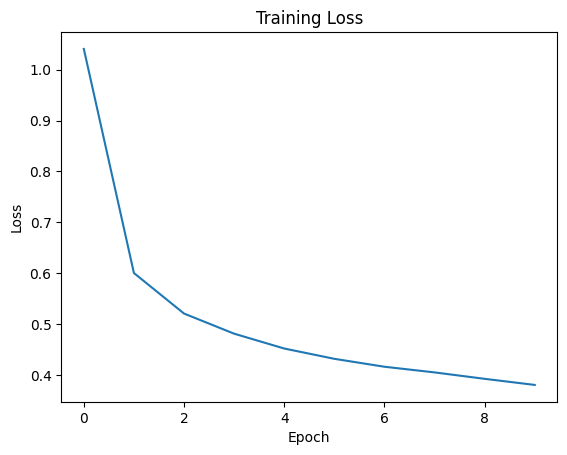

In [11]:
plt.figure()
plt.plot(loss_hist)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

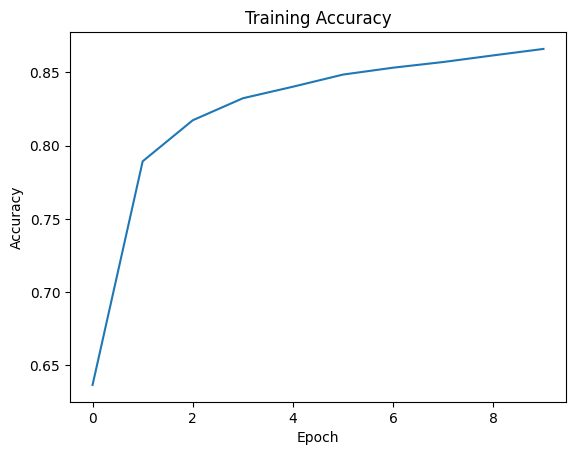

In [12]:
plt.figure()
plt.plot(acc_hist)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")
plt.show()

# Optional visualization

### plot together of training loss and accuracy for each epoch.

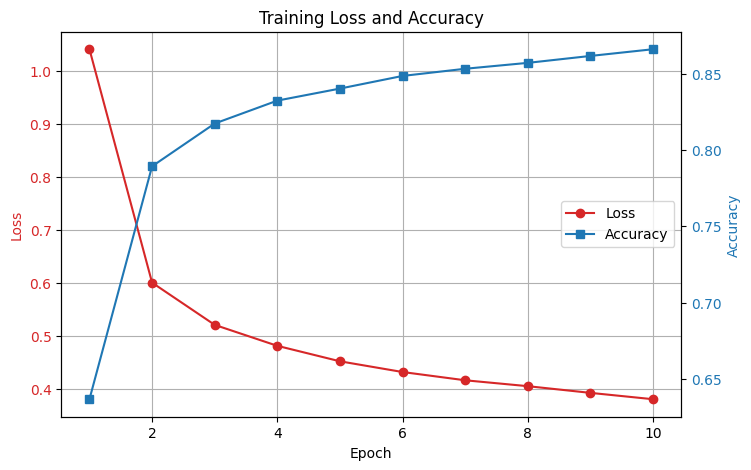

In [13]:
import matplotlib.pyplot as plt

def plot_loss_accuracy(loss_hist, acc_hist):
    epochs = range(1, len(loss_hist) + 1)

    fig, ax1 = plt.subplots(figsize=(8,5))

    color = 'tab:red'
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss', color=color)
    ax1.plot(epochs, loss_hist, 'o-', color=color, label='Loss')
    ax1.tick_params(axis='y', labelcolor=color)

    # Create a second y-axis for accuracy
    ax2 = ax1.twinx()
    color = 'tab:blue'
    ax2.set_ylabel('Accuracy', color=color)
    ax2.plot(epochs, acc_hist, 's-', color=color, label='Accuracy')
    ax2.tick_params(axis='y', labelcolor=color)

    # Title and grid
    plt.title('Training Loss and Accuracy')
    ax1.grid(True)

    # Legends
    lines, labels = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines + lines2, labels + labels2, loc='center right')

    plt.show()
plot_loss_accuracy(loss_hist, acc_hist)

# Evaluate Model's Performances(using test-set data)

### 1. Calculate test accuracy

In [14]:
def evaluate(X, y, W1, b1, W2, b2):
    logits, _ = forward(X, W1, b1, W2, b2)
    preds = softmax(logits)
    acc = (preds.argmax(axis=1) == y).mean()
    return acc

test_acc = evaluate(X_test, y_test, W1, b1, W2, b2)
print("Test Accuracy:", test_acc)

Test Accuracy: 0.8351


### 2. Show Predicted labels compare with actual label
#### - **The predicted labels are labels which is predicted by model(MLP)**
#### - **The actual labels are labels that get from our data**

In [15]:
import matplotlib.pyplot as plt
# Cell: Class labels
fashion_labels = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]


def show_predictions_grid(X, y, W1, b1, W2, b2, num_samples=20, ncols=5):
    logits, _ = forward(X[:num_samples], W1, b1, W2, b2)
    preds = softmax(logits).argmax(axis=1)

    y_true = y
    y_pred = preds

    nrows = int(np.ceil(num_samples / ncols))
    plt.figure(figsize=(ncols*2, nrows*2))

    for i in range(num_samples):
        '''plt.subplot(nrows, ncols, i+1)
        plt.imshow(X[i], cmap='gray')
        plt.title(f"T:{y[i]} | P:{preds[i]}")
        plt.axis("off")'''

        #plt.subplot(2, num_images, i + 1)
        plt.subplot(2, num_samples//2, i + 1)
        plt.imshow(X[i].reshape(28, 28), cmap="gray")
        
        true_label = fashion_labels[y_true[i]]
        pred_label = fashion_labels[y_pred[i]]
        
        color = "green" if y_true[i] == y_pred[i] else "red"
        plt.title(f"T:{true_label}\nP:{pred_label}", fontsize=8, color=color)
        plt.axis("off")
    
    plt.tight_layout()
    plt.show()

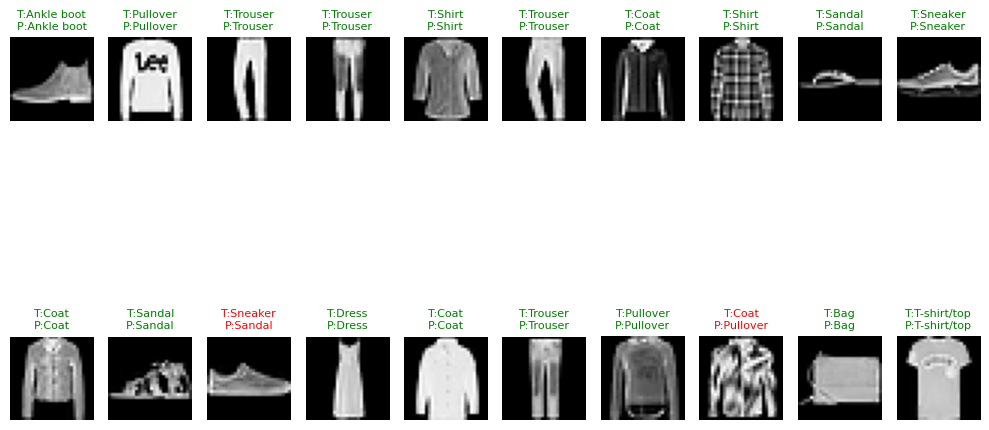

In [16]:
show_predictions_grid(X_test, y_test, W1, b1, W2, b2, num_samples=20, ncols=5)

## 3. Plot confusion matrix

To visualize number of correct prediction and incorrect prediction for each class.

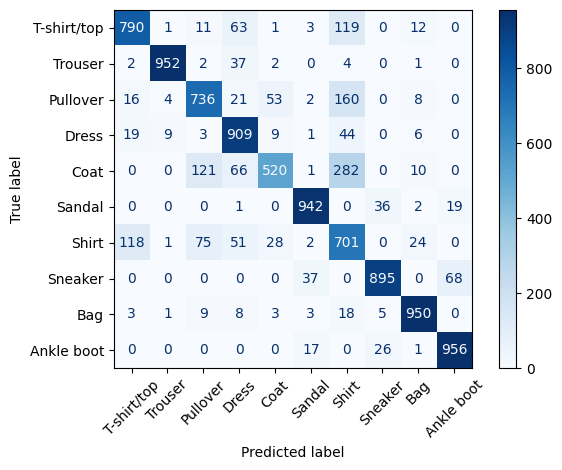

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

logits, _ = forward(X_test, W1, b1, W2, b2)

# Convert probabilities to predicted class labels
y_pred = softmax(logits).argmax(axis=1)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=fashion_labels)

disp.plot(cmap="Blues", values_format="d")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Summary
In today's lab, we implemented a Multilayer Perceptron (MLP) from scratch using NumPy, trained on the Fashion-MNIST dataset. The workflow includes manual data loading from IDX files, normalization, and defining the forward pass with a hidden layer using ReLU activation and a softmax output for classification. We computed the cross-entropy loss and implemented backpropagation manually to calculate gradients and update weights using stochastic gradient descent (SGD). The training loop iterates over mini-batches, shuffles data each epoch, and tracks loss and accuracy, which are visualized to monitor learning progress. Finally, we evaluate the model on the test set and display a grid of predictions, allowing visual inspection of true vs predicted labels. This project provides a clear understanding of the internal mechanics of neural networks without relying on high-level frameworks.


--- 


# Extension Practice: Generalization, Early Stopping, and Dropout

In the previous part of this lab, you trained an MLP from scratch and evaluated it using the test set. However, a model should not only perform well on the training data. We also want it to **generalize** well to unseen data.

In this practice, you will investigate two techniques discussed in *Dive into Deep Learning*, Sections 5.5 and 5.6:

- **Early stopping:** monitor validation performance during training and stop when the model no longer improves.
- **Dropout:** randomly deactivate some hidden units during training so that the model does not depend too strongly on particular hidden units.

The goal is not simply to obtain a higher accuracy. The goal is to **observe how the training process changes and explain why**.

Reference: [D2L Section 5.5 — Generalization in Deep Learning](https://d2l.ai/chapter_multilayer-perceptrons/generalization-deep.html) and [D2L Section 5.6 — Dropout](https://d2l.ai/chapter_multilayer-perceptrons/dropout.html).

## Question 1 — Investigate the Generalization Gap

A model can continue improving on the training data while its performance on unseen data stops improving. The difference between training performance and performance on holdout data is related to the **generalization gap**. A large gap can be a sign that the model is overfitting.

### Instructions
1. Create a validation set from the training data. **Do not use the test set for model selection.**
2. Use approximately **80% of the training data for training and 20% for validation**.
3. Train the current MLP for more epochs, for example **30 epochs**.
4. Record both training loss/accuracy and validation loss/accuracy after every epoch.
5. Plot:
   - training loss vs. validation loss
   - training accuracy vs. validation accuracy
6. Look at the curves and identify whether there is evidence of overfitting.



In [18]:
# Write your codes based on instruction above.
# create a validation set from the training data (80% training, 20% validation)
val_split = 0.2
n_total = len(X_train)
num_train = int((1.0-val_split) * n_total)

#shuffle indices with fixed random seed for reproducibility
np.random.seed(42)
shuffled_indices = np.random.permutation(n_total)

train_indices = shuffled_indices[:num_train]
val_indices = shuffled_indices[num_train:]

X_tr, y_tr = X_train[train_indices], y_train[train_indices]
X_val, y_val = X_train[val_indices], y_train[val_indices]

print(f"Training set size: {len(X_tr)}")
print(f"Validation set size: {len(X_val)}")

# Re-initialize paramenters (w1,b1,w2,b2) for training with validation set
num_inputs  = 784
num_hiddens = 256
num_outputs = 10
sigma = 0.01

W1 = np.random.randn(num_inputs, num_hiddens) * sigma
b1 = np.zeros(num_hiddens)

W2 = np.random.randn(num_hiddens, num_outputs) * sigma
b2 = np.zeros(num_outputs)

# Training function with validation training (30 epochs)

def train_with_validation(X_train, y_train, X_val, y_val, W1, b1, W2, b2,
                          lr=0.1, epochs=30, batch_size=256):

    n = X_train.shape[0]

    loss_history = []
    acc_history  = []
    val_loss_history = []
    val_acc_history  = []

    for epoch in range(epochs):

        perm = np.random.permutation(n)
        X_train = X_train[perm]
        y_train = y_train[perm]

        total_train_loss = 0.0
        total_train_acc  = 0
    # Mini-batch Gradient Descent
        for i in range(0, n, batch_size):

            X_batch = X_train[i:i+batch_size]
            y_batch = y_train[i:i+batch_size]
            # Forward pass
            logits, cache = forward(X_batch, W1, b1, W2, b2)
            preds = softmax(logits)
            # Compute loss and accuracy
            loss = cross_entropy(preds, y_batch)
            total_train_loss += loss * len(y_batch)
            total_train_acc += (preds.argmax(axis=1) == y_batch).sum()
            # Backward pass and parameter update
            grad_out = preds.copy()
            grad_out[np.arange(len(y_batch)), y_batch] -= 1

            W1, b1, W2, b2 = backward(
                cache, grad_out, W1, b1, W2, b2, lr
            )
        # Calculate epoch metrics for training set
        epoch_loss = total_train_loss / n
        epoch_acc  = total_train_acc / n

        # Validation evaluation
        val_logits, _ = forward(X_val, W1, b1, W2, b2)
        val_preds = softmax(val_logits)
        val_loss = cross_entropy(val_preds, y_val)
        val_acc  = (val_preds.argmax(axis=1) == y_val).mean()
        # Store metrics in history lists
        loss_history.append(epoch_loss)
        acc_history.append(epoch_acc)
        val_loss_history.append(val_loss)
        val_acc_history.append(val_acc)

        print(f"Epoch {epoch+1}: "
              f"Train Loss={epoch_loss:.4f}, Train Acc={epoch_acc:.4f}, "
              f"Val Loss={val_loss:.4f}, Val Acc={val_acc:.4f}")

    return W1, b1, W2, b2, loss_history, acc_history, val_loss_history, val_acc_history

Training set size: 48000
Validation set size: 12000


In [19]:
# Execute training with validation
W1, b1, W2, b2, loss_hist, acc_hist, val_loss_hist, val_acc_hist = train_with_validation(
    X_tr, y_tr, X_val, y_val, W1, b1, W2, b2, lr=0.1, epochs=30, batch_size=256
)

Epoch 1: Train Loss=1.1241, Train Acc=0.6154, Val Loss=0.7585, Val Acc=0.7353
Epoch 2: Train Loss=0.6409, Train Acc=0.7729, Val Loss=0.6433, Val Acc=0.7578
Epoch 3: Train Loss=0.5430, Train Acc=0.8097, Val Loss=0.5281, Val Acc=0.8193
Epoch 4: Train Loss=0.5040, Train Acc=0.8232, Val Loss=0.5155, Val Acc=0.8144
Epoch 5: Train Loss=0.4727, Train Acc=0.8336, Val Loss=0.4755, Val Acc=0.8359
Epoch 6: Train Loss=0.4527, Train Acc=0.8425, Val Loss=0.4754, Val Acc=0.8367
Epoch 7: Train Loss=0.4384, Train Acc=0.8445, Val Loss=0.4428, Val Acc=0.8460
Epoch 8: Train Loss=0.4225, Train Acc=0.8523, Val Loss=0.4473, Val Acc=0.8385
Epoch 9: Train Loss=0.4100, Train Acc=0.8564, Val Loss=0.4312, Val Acc=0.8480
Epoch 10: Train Loss=0.4014, Train Acc=0.8577, Val Loss=0.4253, Val Acc=0.8467
Epoch 11: Train Loss=0.3931, Train Acc=0.8616, Val Loss=0.4559, Val Acc=0.8303
Epoch 12: Train Loss=0.3816, Train Acc=0.8649, Val Loss=0.4402, Val Acc=0.8362
Epoch 13: Train Loss=0.3729, Train Acc=0.8688, Val Loss=0.401

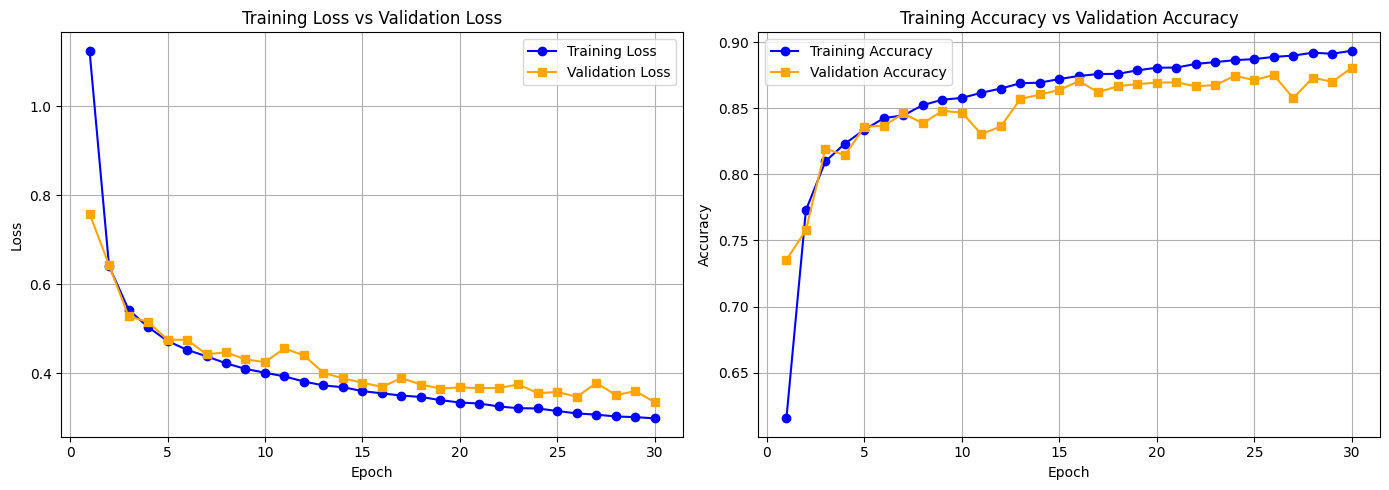

In [20]:
# Plotting the learning curves
epochs = range(1, len(loss_hist) + 1)
plt.figure(figsize=(14, 5))
# Training Loss vs Validation Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, loss_hist, 'o-', label='Training Loss', color='blue')
plt.plot(epochs, val_loss_hist, 's-', label='Validation Loss', color='orange')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss vs Validation Loss")
plt.legend()
plt.grid(True)

# Training Accuracy vs Validation Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, acc_hist, 'o-', label='Training Accuracy', color='blue')
plt.plot(epochs, val_acc_hist, 's-', label='Validation Accuracy', color='orange')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### Questions to answer
- At approximately which epoch does the validation performance stop improving?
- Answer: Validation performance stop making meaningful improvements around epoch 10 to 15. Training showed rapid improvement in the first 10 epochs, but from epochs 12–15 onward validation loss plateaued and accuracy saturated around 85–86%, indicating stalled generalization progress. 
- Does the training accuracy continue to improve after that point?
- Despite validation metrics stalling after epoch ~12, training loss and accuracy keep improving steadily, widening the gap between training and validation curves and signaling clear overfitting.
- What does this tell you about the difference between **learning the training data** and **generalizing to unseen data**?
- Optimization keeps reducing training loss by fitting noise and spurious patterns, while true generalization requires capturing underlying invariants. The widening gap between training and validation performance highlights overfitting, making regularization methods like early stopping and dropout essential.

---End of Question1---


--- 

## Question 2 — Implement Early Stopping

**Early stopping** is a regularization technique. Instead of allowing the model to train for a fixed large number of epochs, we monitor validation performance and stop training when it has not improved for several consecutive epochs. This number of allowed non-improving epochs is called **patience**.

For this exercise, use **validation loss** as the quantity to monitor. A smaller validation loss means better validation performance.

### Instructions
Modify your training function so that it:

1. Evaluates validation loss after every epoch.
2. Keeps a copy of the parameters (`W1`, `b1`, `W2`, `b2`) whenever validation loss improves.
3. Uses `patience = 3`.
4. Stops training when validation loss has not improved for 3 consecutive epochs.
5. Restores the parameters from the epoch with the best validation loss before returning the model.
6. Stores the training and validation history so you can plot both curves.

### Starter idea
Use variables such as:

```python
best_val_loss = float("inf")
patience = 3
wait = 0
best_params = None
```

When validation loss improves, save copies of the parameters. Otherwise, increase `wait`. Stop when `wait >= patience`.


In [21]:
# your code here
# Save the 30-epoch model from Question 1 for a fair test-set comparison later.
baseline_params = tuple(param.copy() for param in (W1, b1, W2, b2))

def train_with_early_stopping(X_train, y_train, X_val, y_val,
                              W1, b1, W2, b2, lr=0.1, epochs=100,
                              batch_size=256, patience=3):
    n = X_train.shape[0]
    loss_history, acc_history = [], []
    val_loss_history, val_acc_history = [], []

    best_val_loss = float("inf")
    best_params = None
    best_epoch = 0
    wait = 0
    stopped_epoch = epochs

    for epoch in range(epochs):
        perm = np.random.permutation(n)
        X_shuffled = X_train[perm]
        y_shuffled = y_train[perm]

        total_train_loss = 0.0
        total_train_acc = 0

        for i in range(0, n, batch_size):
            X_batch = X_shuffled[i:i + batch_size]
            y_batch = y_shuffled[i:i + batch_size]

            logits, cache = forward(X_batch, W1, b1, W2, b2)
            preds = softmax(logits)
            loss = cross_entropy(preds, y_batch)
            total_train_loss += loss * len(y_batch)
            total_train_acc += (preds.argmax(axis=1) == y_batch).sum()

            grad_out = preds.copy()
            grad_out[np.arange(len(y_batch)), y_batch] -= 1
            W1, b1, W2, b2 = backward(
                cache, grad_out, W1, b1, W2, b2, lr
            )

        train_loss = total_train_loss / n
        train_acc = total_train_acc / n

        val_logits, _ = forward(X_val, W1, b1, W2, b2)
        val_preds = softmax(val_logits)
        val_loss = cross_entropy(val_preds, y_val)
        val_acc = (val_preds.argmax(axis=1) == y_val).mean()

        loss_history.append(train_loss)
        acc_history.append(train_acc)
        val_loss_history.append(val_loss)
        val_acc_history.append(val_acc)

        print(f"Epoch {epoch + 1}: Train Loss={train_loss:.4f}, "
              f"Train Acc={train_acc:.4f}, Val Loss={val_loss:.4f}, "
              f"Val Acc={val_acc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_params = (W1.copy(), b1.copy(), W2.copy(), b2.copy())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                stopped_epoch = epoch + 1
                print(f"Early stopping at epoch {stopped_epoch}; "
                      f"restoring epoch {best_epoch}.")
                break

    # Restore the parameters that achieved the lowest validation loss.
    W1, b1, W2, b2 = best_params
    return (W1, b1, W2, b2, loss_history, acc_history,
            val_loss_history, val_acc_history, stopped_epoch,
            best_epoch, best_val_loss)

# Initialize a fresh model for the early-stopping experiment.
np.random.seed(42)
W1_es = np.random.randn(num_inputs, num_hiddens) * sigma
b1_es = np.zeros(num_hiddens)
W2_es = np.random.randn(num_hiddens, num_outputs) * sigma
b2_es = np.zeros(num_outputs)

(W1_es, b1_es, W2_es, b2_es, es_loss_hist, es_acc_hist,
 es_val_loss_hist, es_val_acc_hist, early_stop_epoch, best_epoch,
 best_val_loss) = train_with_early_stopping(
    X_tr, y_tr, X_val, y_val, W1_es, b1_es, W2_es, b2_es,
    lr=0.1, epochs=100, batch_size=256, patience=3
)



# Use the test set only now, after validation-based model selection is complete.
baseline_test_acc = evaluate(X_test, y_test, *baseline_params)
early_stopping_test_acc = evaluate(
    X_test, y_test, W1_es, b1_es, W2_es, b2_es
)
print(f"Stopped epoch: {early_stop_epoch}")
print(f"Best epoch: {best_epoch} (validation loss={best_val_loss:.4f})")
print(f"Fixed 30-epoch test accuracy: {baseline_test_acc:.4f}")
print(f"Early-stopping test accuracy: {early_stopping_test_acc:.4f}")


Epoch 1: Train Loss=1.1325, Train Acc=0.6077, Val Loss=0.7397, Val Acc=0.7436
Epoch 2: Train Loss=0.6366, Train Acc=0.7743, Val Loss=0.6039, Val Acc=0.7830
Epoch 3: Train Loss=0.5470, Train Acc=0.8083, Val Loss=0.5207, Val Acc=0.8206
Epoch 4: Train Loss=0.4995, Train Acc=0.8252, Val Loss=0.4840, Val Acc=0.8330
Epoch 5: Train Loss=0.4731, Train Acc=0.8344, Val Loss=0.4661, Val Acc=0.8387
Epoch 6: Train Loss=0.4539, Train Acc=0.8409, Val Loss=0.4591, Val Acc=0.8414
Epoch 7: Train Loss=0.4394, Train Acc=0.8447, Val Loss=0.4386, Val Acc=0.8492
Epoch 8: Train Loss=0.4247, Train Acc=0.8494, Val Loss=0.4509, Val Acc=0.8348
Epoch 9: Train Loss=0.4086, Train Acc=0.8557, Val Loss=0.4428, Val Acc=0.8387
Epoch 10: Train Loss=0.4010, Train Acc=0.8576, Val Loss=0.4130, Val Acc=0.8521
Epoch 11: Train Loss=0.3892, Train Acc=0.8617, Val Loss=0.4157, Val Acc=0.8503
Epoch 12: Train Loss=0.3824, Train Acc=0.8637, Val Loss=0.3920, Val Acc=0.8627
Epoch 13: Train Loss=0.3747, Train Acc=0.8667, Val Loss=0.400

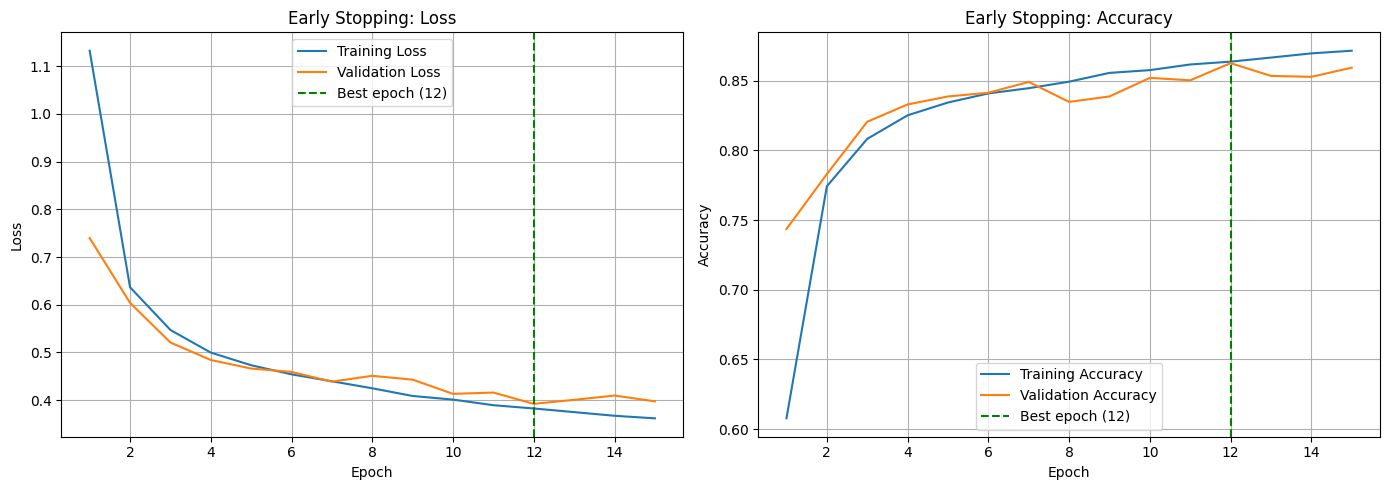

In [22]:
# Plot the histories collected up to the stopping epoch.
es_epochs = range(1, len(es_loss_hist) + 1)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(es_epochs, es_loss_hist, label="Training Loss")
plt.plot(es_epochs, es_val_loss_hist, label="Validation Loss")
plt.axvline(best_epoch, color="green", linestyle="--",
            label=f"Best epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Early Stopping: Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(es_epochs, es_acc_hist, label="Training Accuracy")
plt.plot(es_epochs, es_val_acc_hist, label="Validation Accuracy")
plt.axvline(best_epoch, color="green", linestyle="--",
            label=f"Best epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Early Stopping: Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Questions to answer
- At which epoch did your early-stopping training stop?
- Answer: Training stopped at epoch 15 after validation loss failed to improve for three consecutive epochs.
- Which epoch contained the best validation loss?
- Answer: Epoch 12 had the best validation loss of 0.3920
- Why should we restore the best parameters instead of simply using the parameters from the final epoch?
- Answer: The final epoch may have worse validation performance because overfitting has begun, so restoring the best parameters gives the model that generalized best.
- Compare the early-stopping model with the original fixed-epoch model using the **same test set only after model selection is complete**.
- Answer: The 30-epoch model achieved 87.15% test accuracy, while early stopping achieved 85.33%; in this run, early stopping reduced training time but did not improve test accuracy.

---End of Question2---

--- 

## Question 3 — Implement Dropout from Scratch

Dropout is another technique for reducing over-reliance on particular hidden units. During training, some hidden activations are randomly set to zero. With dropout probability `p`, an activation is dropped with probability `p`; the remaining activations are scaled by `1/(1-p)` so that their expected value remains approximately unchanged.

For example, if `p = 0.5`, approximately half of the hidden units are dropped during each training pass. **Dropout is applied during training, but it should be disabled when evaluating the model.**

### Instructions
1. Implement a NumPy `dropout_layer()` function.
2. Test it using a small matrix such as `X = np.arange(16).reshape(2, 8)`.
3. Try dropout probabilities `0`, `0.5`, and `1`.
4. Verify that when `p = 0.5`, some values become zero and the remaining values are scaled.
5. Modify the MLP forward pass so dropout is applied to the hidden layer **only when training**.
6. Store the dropout mask in the cache so that the backward pass can use the same mask.
7. Modify the backward pass so gradients corresponding to dropped hidden units are also removed.

### Important
Your model should behave differently in these two situations:

- **Training:** dropout is active.
- **Validation/test:** dropout is disabled.



In [23]:
# Your code
def dropout_layer(X, p=0.5, training=True):
    """Apply inverted dropout and return both the output and its mask."""
    if not 0 <= p <= 1:
        raise ValueError("p must be between 0 and 1.")

    if not training or p == 0:
        return X, np.ones_like(X)
    if p == 1:
        return np.zeros_like(X), np.zeros_like(X)

    # Inverted dropout keeps the expected activation unchanged.
    mask = (np.random.rand(*X.shape) >= p).astype(X.dtype) / (1 - p)
    return X * mask, mask


# Test dropout using the requested small matrix.
dropout_test_X = np.arange(16, dtype=float).reshape(2, 8)
for test_p in (0, 0.5, 1):
    test_output, _ = dropout_layer(dropout_test_X, p=test_p, training=True)
    print(f"Dropout p={test_p}:\n{test_output}\n")


def forward_with_dropout(X, W1, b1, W2, b2, p=0.5, training=True):
    X = X.reshape(X.shape[0], -1)
    H_linear = X.dot(W1) + b1
    H_relu = relu(H_linear)
    H, dropout_mask = dropout_layer(H_relu, p=p, training=training)
    logits = H.dot(W2) + b2
    cache = (X, H, H_linear, dropout_mask)
    return logits, cache


def backward_with_dropout(cache, grad_out, W1, b1, W2, b2, lr):
    X, H, H_linear, dropout_mask = cache
    batch_size = X.shape[0]

    dW2 = H.T.dot(grad_out)
    db2 = grad_out.sum(axis=0)
    dH = grad_out.dot(W2.T)
    dH *= dropout_mask                 # Use the same mask as the forward pass.
    dH_linear = dH * (H_linear > 0)
    dW1 = X.T.dot(dH_linear)
    db1 = dH_linear.sum(axis=0)

    W2 -= lr * dW2 / batch_size
    b2 -= lr * db2 / batch_size
    W1 -= lr * dW1 / batch_size
    b1 -= lr * db1 / batch_size
    return W1, b1, W2, b2


def train_with_dropout(X_train, y_train, X_val, y_val, W1, b1, W2, b2,
                       p=0.5, lr=0.1, epochs=30, batch_size=256):
    n = X_train.shape[0]
    train_loss_history, train_acc_history = [], []
    val_loss_history, val_acc_history = [], []

    for epoch in range(epochs):
        perm = np.random.permutation(n)
        X_shuffled = X_train[perm]
        y_shuffled = y_train[perm]
        total_loss = 0.0
        total_correct = 0

        for i in range(0, n, batch_size):
            X_batch = X_shuffled[i:i + batch_size]
            y_batch = y_shuffled[i:i + batch_size]

            logits, cache = forward_with_dropout(
                X_batch, W1, b1, W2, b2, p=p, training=True
            )
            preds = softmax(logits)
            total_loss += cross_entropy(preds, y_batch) * len(y_batch)
            total_correct += (preds.argmax(axis=1) == y_batch).sum()

            grad_out = preds.copy()
            grad_out[np.arange(len(y_batch)), y_batch] -= 1
            W1, b1, W2, b2 = backward_with_dropout(
                cache, grad_out, W1, b1, W2, b2, lr
            )

        train_loss = total_loss / n
        train_acc = total_correct / n

        # Dropout must be disabled for validation.
        val_logits, _ = forward_with_dropout(
            X_val, W1, b1, W2, b2, p=p, training=False
        )
        val_preds = softmax(val_logits)
        val_loss = cross_entropy(val_preds, y_val)
        val_acc = (val_preds.argmax(axis=1) == y_val).mean()

        train_loss_history.append(train_loss)
        train_acc_history.append(train_acc)
        val_loss_history.append(val_loss)
        val_acc_history.append(val_acc)

        print(f"Epoch {epoch + 1}: Train Loss={train_loss:.4f}, "
              f"Train Acc={train_acc:.4f}, Val Loss={val_loss:.4f}, "
              f"Val Acc={val_acc:.4f}")

    return (W1, b1, W2, b2, train_loss_history, train_acc_history,
            val_loss_history, val_acc_history)


# Train a fresh model with dropout probability p = 0.5.
np.random.seed(42)
W1_dropout = np.random.randn(num_inputs, num_hiddens) * sigma
b1_dropout = np.zeros(num_hiddens)
W2_dropout = np.random.randn(num_hiddens, num_outputs) * sigma
b2_dropout = np.zeros(num_outputs)

(W1_dropout, b1_dropout, W2_dropout, b2_dropout, dropout_loss_hist,
 dropout_acc_hist, dropout_val_loss_hist, dropout_val_acc_hist) = (
    train_with_dropout(
        X_tr, y_tr, X_val, y_val, W1_dropout, b1_dropout,
        W2_dropout, b2_dropout, p=0.5, lr=0.1, epochs=30, batch_size=256
    )
)

# Disable dropout for final test evaluation.
dropout_test_logits, _ = forward_with_dropout(
    X_test, W1_dropout, b1_dropout, W2_dropout, b2_dropout,
    p=0.5, training=False
)
dropout_test_preds = softmax(dropout_test_logits)
dropout_test_acc = (dropout_test_preds.argmax(axis=1) == y_test).mean()
baseline_test_acc_q3 = evaluate(X_test, y_test, W1, b1, W2, b2)

print(f"Baseline final training accuracy: {acc_hist[-1]:.4f}")
print(f"Dropout final training accuracy: {dropout_acc_hist[-1]:.4f}")
print(f"Baseline best validation accuracy: {max(val_acc_hist):.4f}")
print(f"Dropout best validation accuracy: {max(dropout_val_acc_hist):.4f}")
print(f"Baseline test accuracy: {baseline_test_acc_q3:.4f}")
print(f"Dropout test accuracy: {dropout_test_acc:.4f}")


Dropout p=0:
[[ 0.  1.  2.  3.  4.  5.  6.  7.]
 [ 8.  9. 10. 11. 12. 13. 14. 15.]]

Dropout p=0.5:
[[ 0.  0.  0.  0.  0. 10.  0. 14.]
 [ 0.  0.  0. 22.  0. 26. 28.  0.]]

Dropout p=1:
[[0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]]

Epoch 1: Train Loss=1.1806, Train Acc=0.5899, Val Loss=0.7492, Val Acc=0.7407
Epoch 2: Train Loss=0.6905, Train Acc=0.7570, Val Loss=0.5925, Val Acc=0.7971
Epoch 3: Train Loss=0.5899, Train Acc=0.7954, Val Loss=0.5306, Val Acc=0.8151
Epoch 4: Train Loss=0.5365, Train Acc=0.8147, Val Loss=0.4984, Val Acc=0.8277
Epoch 5: Train Loss=0.5015, Train Acc=0.8276, Val Loss=0.4631, Val Acc=0.8388
Epoch 6: Train Loss=0.4761, Train Acc=0.8319, Val Loss=0.4614, Val Acc=0.8370
Epoch 7: Train Loss=0.4589, Train Acc=0.8389, Val Loss=0.4496, Val Acc=0.8413
Epoch 8: Train Loss=0.4442, Train Acc=0.8413, Val Loss=0.4212, Val Acc=0.8508
Epoch 9: Train Loss=0.4334, Train Acc=0.8456, Val Loss=0.4155, Val Acc=0.8536
Epoch 10: Train Loss=0.4239, Train Acc=0.8485, Val Loss=0

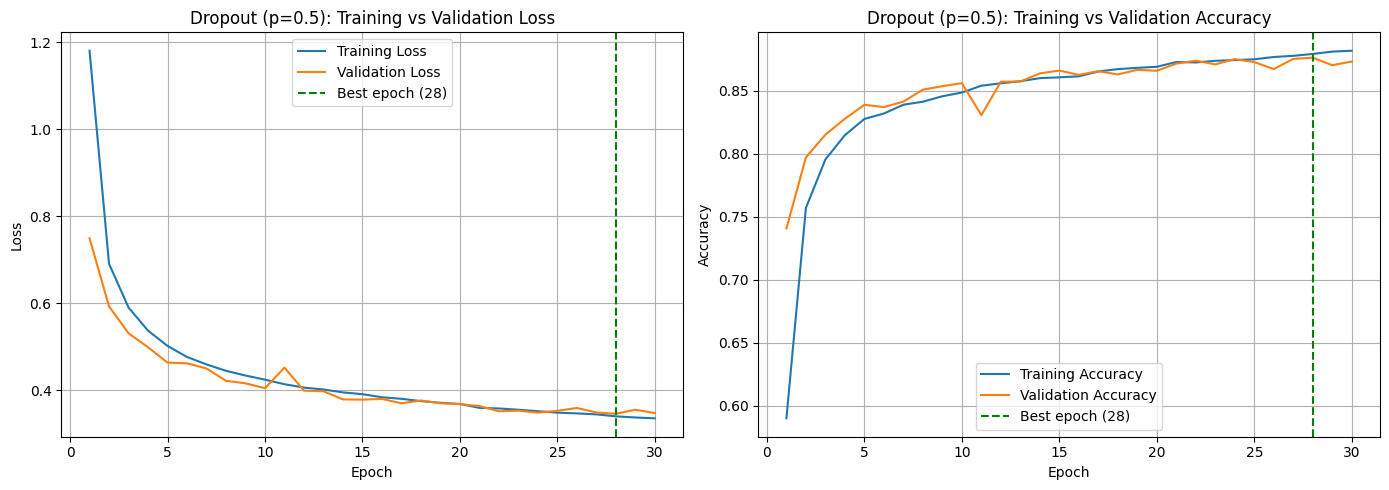

In [24]:
# Plot the dropout model's learning curves and mark its best validation-loss epoch.
dropout_epochs = range(1, len(dropout_loss_hist) + 1)
dropout_best_epoch = int(np.argmin(dropout_val_loss_hist)) + 1

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(dropout_epochs, dropout_loss_hist, label="Training Loss")
plt.plot(dropout_epochs, dropout_val_loss_hist, label="Validation Loss")
plt.axvline(dropout_best_epoch, color="green", linestyle="--",
            label=f"Best epoch ({dropout_best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Dropout (p=0.5): Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(dropout_epochs, dropout_acc_hist, label="Training Accuracy")
plt.plot(dropout_epochs, dropout_val_acc_hist, label="Validation Accuracy")
plt.axvline(dropout_best_epoch, color="green", linestyle="--",
            label=f"Best epoch ({dropout_best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Dropout (p=0.5): Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Questions to answer
- What happens to the training loss when dropout is introduced?

**Answer**: Training loss becomes higher because randomly dropping neurons makes fitting the training data more difficult.
- Does the training accuracy become higher or lower than the model without dropout?

**Answer**: It became lower, decreasing from 89.34% without dropout to 88.18% with dropout.
- What happens to the validation accuracy/loss?

**Answer**: The best validation accuracy decreased slightly from 88.06% to 87.62%, while the best validation loss increased from 0.3351 to 0.3455.
- Why would we not randomly drop neurons when evaluating the final test performance?

**Answer**: Dropout is only a training regularizer; disabling it during testing uses the complete network and produces stable predictions.

---End of Question3---

--- 

## Question 4 — Investigate the Effect of Different Dropout Rates

The dropout probability is a hyperparameter. A very small dropout rate may have only a small regularization effect, while a very large rate can make learning difficult.

### Instructions
Train the same MLP architecture using the following settings:

| Model | Dropout probability |
|---|---:|
| Baseline | 0.0 |
| Model A | 0.2 |
| Model B | 0.5 |
| Model C | 0.8 |

Keep the other important settings as consistent as possible, including the number of epochs, learning rate, batch size, and data split.

Record for each model:
- final training accuracy
- best validation accuracy
- validation loss at the best epoch
- test accuracy
- number of epochs trained



In [ ]:
# Your code here
# Use identical initial parameters and training settings for every dropout rate.
np.random.seed(42)
initial_W1 = np.random.randn(num_inputs, num_hiddens) * sigma
initial_b1 = np.zeros(num_hiddens)
initial_W2 = np.random.randn(num_hiddens, num_outputs) * sigma
initial_b2 = np.zeros(num_outputs)

dropout_settings = [
    ("Baseline", 0.0),
    ("Model A", 0.2),
    ("Model B", 0.5),
    ("Model C", 0.8),
]

q4_results = []
q4_models = {}
q4_histories = {}

for model_index, (model_name, dropout_p) in enumerate(dropout_settings):
    print(f"\nTraining {model_name} with dropout p={dropout_p}")

    # Every model starts from exactly the same weights.
    W1_q4 = initial_W1.copy()
    b1_q4 = initial_b1.copy()
    W2_q4 = initial_W2.copy()
    b2_q4 = initial_b2.copy()

    # Reset the random seed so the first shuffle is consistent across models.
    np.random.seed(100)
    (W1_q4, b1_q4, W2_q4, b2_q4, train_losses, train_accs,
     val_losses, val_accs) = train_with_dropout(
        X_tr, y_tr, X_val, y_val, W1_q4, b1_q4, W2_q4, b2_q4,
        p=dropout_p, lr=0.1, epochs=30, batch_size=256
    )

    # Select the best epoch using validation accuracy, not the test set.
    best_epoch_index = int(np.argmax(val_accs))
    best_epoch = best_epoch_index + 1
    best_val_acc = val_accs[best_epoch_index]
    val_loss_at_best_epoch = val_losses[best_epoch_index]

    # Evaluate the test set only after training/model selection is complete.
    test_logits, _ = forward_with_dropout(
        X_test, W1_q4, b1_q4, W2_q4, b2_q4,
        p=dropout_p, training=False
    )
    test_predictions = softmax(test_logits).argmax(axis=1)
    test_accuracy = (test_predictions == y_test).mean()

    q4_results.append({
        "model": model_name,
        "dropout_p": dropout_p,
        "final_train_acc": train_accs[-1],
        "best_val_acc": best_val_acc,
        "val_loss_at_best_epoch": val_loss_at_best_epoch,
        "test_acc": test_accuracy,
        "epochs_trained": len(train_losses),
        "best_epoch": best_epoch,
    })
    q4_models[model_name] = (W1_q4, b1_q4, W2_q4, b2_q4)
    q4_histories[model_name] = {
        "train_loss": train_losses,
        "train_acc": train_accs,
        "val_loss": val_losses,
        "val_acc": val_accs,
    }



Training Baseline with dropout p=0.0
Epoch 1: Train Loss=1.1326, Train Acc=0.6067, Val Loss=0.7285, Val Acc=0.7471
Epoch 2: Train Loss=0.6361, Train Acc=0.7746, Val Loss=0.5984, Val Acc=0.7875
Epoch 3: Train Loss=0.5474, Train Acc=0.8084, Val Loss=0.5352, Val Acc=0.8144
Epoch 4: Train Loss=0.4984, Train Acc=0.8259, Val Loss=0.5876, Val Acc=0.7828
Epoch 5: Train Loss=0.4747, Train Acc=0.8331, Val Loss=0.4742, Val Acc=0.8344
Epoch 6: Train Loss=0.4507, Train Acc=0.8427, Val Loss=0.4520, Val Acc=0.8407
Epoch 7: Train Loss=0.4354, Train Acc=0.8467, Val Loss=0.4522, Val Acc=0.8368
Epoch 8: Train Loss=0.4222, Train Acc=0.8501, Val Loss=0.4840, Val Acc=0.8215
Epoch 9: Train Loss=0.4076, Train Acc=0.8563, Val Loss=0.4209, Val Acc=0.8504
Epoch 10: Train Loss=0.3991, Train Acc=0.8589, Val Loss=0.4055, Val Acc=0.8587
Epoch 11: Train Loss=0.3894, Train Acc=0.8616, Val Loss=0.4055, Val Acc=0.8586
Epoch 12: Train Loss=0.3807, Train Acc=0.8648, Val Loss=0.3978, Val Acc=0.8577
Epoch 13: Train Loss=0.

In [27]:
# Display the requested comparison table.
header = (f"{'Model':<10} {'p':>5} {'Final Train Acc':>17} "
          f"{'Best Val Acc':>15} {'Val Loss*':>12} "
          f"{'Test Acc':>11} {'Epochs':>8}")
print("\n" + header)
print("-" * len(header))
for result in q4_results:
    print(f"{result['model']:<10} {result['dropout_p']:>5.1f} "
          f"{result['final_train_acc']:>17.4f} "
          f"{result['best_val_acc']:>15.4f} "
          f"{result['val_loss_at_best_epoch']:>12.4f} "
          f"{result['test_acc']:>11.4f} "
          f"{result['epochs_trained']:>8}")
print("* Validation loss from the epoch with the best validation accuracy.")


Model          p   Final Train Acc    Best Val Acc    Val Loss*    Test Acc   Epochs
------------------------------------------------------------------------------------
Baseline     0.0            0.8937          0.8782       0.3334      0.8639       30
Model A      0.2            0.8901          0.8817       0.3309      0.8734       30
Model B      0.5            0.8800          0.8777       0.3369      0.8725       30
Model C      0.8            0.8460          0.8661       0.3721      0.8553       30
* Validation loss from the epoch with the best validation accuracy.


### Questions to answer
- How does increasing dropout probability affect training?

**Answer**: Increasing dropout generally makes training harder, with final training accuracy falling from 89.37% at p=0 to 84.60% at p=0.8.
- Which dropout rates appear to make learning too difficult?

**Answer**: p=0.8 appears too strong because it produced the lowest training (84.60%), validation (86.61%), and test (85.53%) accuracy.
- Does the model with the highest training accuracy necessarily have the best validation/test performance? Explain using your results.

**Answer**: No; the baseline had the highest training accuracy, while p=0.2 achieved the best validation accuracy (88.17%) and test accuracy (87.34%).
---End of Question4---


## Question 5 — Combine Early Stopping and Dropout

Early stopping and dropout address overfitting in different ways. Early stopping limits **how long the model learns**, while dropout changes the training process by randomly removing hidden units during each training pass.

### Instructions
Build a final experiment with:

- the same MLP architecture used in this lab
- dropout probability `p = 0.5`
- early stopping with `patience = 3`
- the same train/validation split used above

Compare this model with the original baseline model.

Create a small results table containing:

| Model | Best Validation Accuracy | Test Accuracy | Epochs Trained |
|---|---:|---:|---:|
| Baseline MLP | | | |
| Early Stopping | | | |
| Dropout | | | |
| Dropout + Early Stopping | | | |

### Final discussion
1. Which model shows the clearest evidence of reduced overfitting?

**Answer**: The dropout + early-stopping model shows the clearest reduction because its training and validation performance remained close and training stopped when validation loss stopped improving.

2. How did the training and validation curves change after applying regularization?

**Answer**: Dropout produced higher training loss and lower training accuracy, while keeping the validation curves closer to the training curves; early stopping prevented continued training after validation performance stalled.

3. What is the difference between **improving training performance** and **improving generalization**?

**Answer**: Training performance measures how well the model fits examples it has seen, while generalization measures its performance on unseen validation or test data.

4. Based on your experiments, what did you learn about choosing a stopping point and a dropout rate?

**Answer**: They should be selected using validation performance: p=0.5 provided useful regularization, while p=0.8 was too strong, and early stopping restored the best validation-loss epoch instead of the final epoch.

**Important:** Do not select a model because it has the highest test accuracy and then repeatedly tune it using the test set. Use the validation set for decisions during development, and use the test set for the final evaluation.

Epoch 1: Train Loss=1.1806, Train Acc=0.5899, Val Loss=0.7492, Val Acc=0.7407
Epoch 2: Train Loss=0.6905, Train Acc=0.7570, Val Loss=0.5925, Val Acc=0.7971
Epoch 3: Train Loss=0.5899, Train Acc=0.7954, Val Loss=0.5306, Val Acc=0.8151
Epoch 4: Train Loss=0.5365, Train Acc=0.8147, Val Loss=0.4984, Val Acc=0.8277
Epoch 5: Train Loss=0.5015, Train Acc=0.8276, Val Loss=0.4631, Val Acc=0.8388
Epoch 6: Train Loss=0.4761, Train Acc=0.8319, Val Loss=0.4614, Val Acc=0.8370
Epoch 7: Train Loss=0.4589, Train Acc=0.8389, Val Loss=0.4496, Val Acc=0.8413
Epoch 8: Train Loss=0.4442, Train Acc=0.8413, Val Loss=0.4212, Val Acc=0.8508
Epoch 9: Train Loss=0.4334, Train Acc=0.8456, Val Loss=0.4155, Val Acc=0.8536
Epoch 10: Train Loss=0.4239, Train Acc=0.8485, Val Loss=0.4042, Val Acc=0.8560
Epoch 11: Train Loss=0.4134, Train Acc=0.8540, Val Loss=0.4516, Val Acc=0.8306
Epoch 12: Train Loss=0.4056, Train Acc=0.8559, Val Loss=0.3985, Val Acc=0.8572
Epoch 13: Train Loss=0.4012, Train Acc=0.8575, Val Loss=0.397

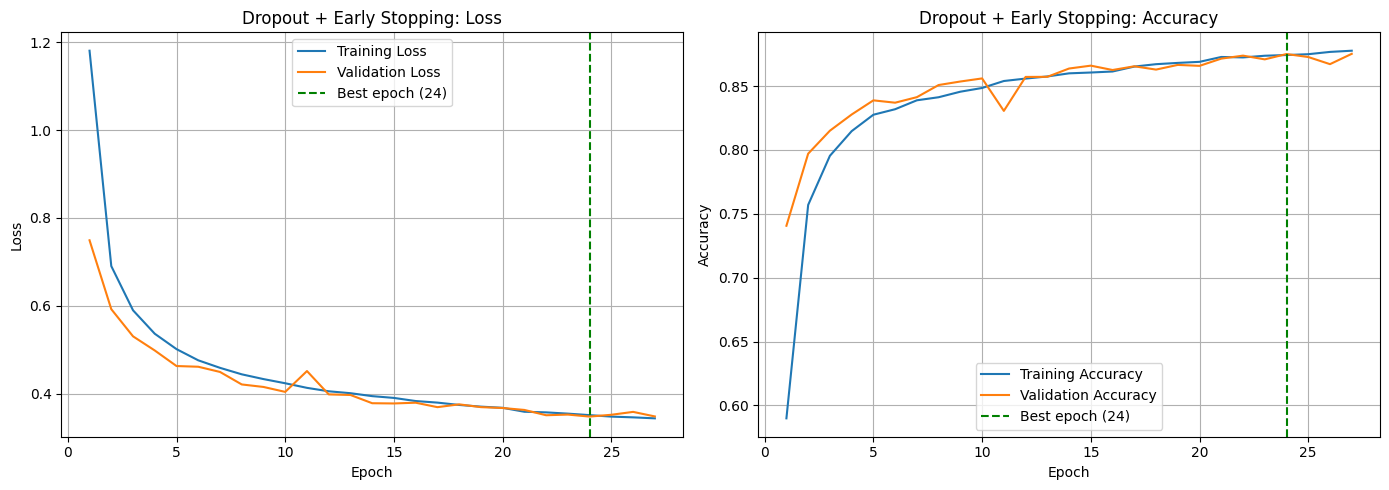

In [ ]:
# Question 5: Combine dropout with early stopping.
def train_with_dropout_early_stopping(
        X_train, y_train, X_val, y_val, W1, b1, W2, b2,
        p=0.5, patience=3, lr=0.1, epochs=100, batch_size=256):
    n = X_train.shape[0]
    train_loss_history, train_acc_history = [], []
    val_loss_history, val_acc_history = [], []

    best_val_loss = float("inf")
    best_params = None
    best_epoch = 0
    wait = 0
    stopped_epoch = epochs

    for epoch in range(epochs):
        perm = np.random.permutation(n)
        X_shuffled = X_train[perm]
        y_shuffled = y_train[perm]
        total_loss = 0.0
        total_correct = 0

        for i in range(0, n, batch_size):
            X_batch = X_shuffled[i:i + batch_size]
            y_batch = y_shuffled[i:i + batch_size]

            logits, cache = forward_with_dropout(
                X_batch, W1, b1, W2, b2, p=p, training=True
            )
            preds = softmax(logits)
            total_loss += cross_entropy(preds, y_batch) * len(y_batch)
            total_correct += (preds.argmax(axis=1) == y_batch).sum()

            grad_out = preds.copy()
            grad_out[np.arange(len(y_batch)), y_batch] -= 1
            W1, b1, W2, b2 = backward_with_dropout(
                cache, grad_out, W1, b1, W2, b2, lr
            )

        train_loss = total_loss / n
        train_acc = total_correct / n

        # Disable dropout while measuring validation performance.
        val_logits, _ = forward_with_dropout(
            X_val, W1, b1, W2, b2, p=p, training=False
        )
        val_preds = softmax(val_logits)
        val_loss = cross_entropy(val_preds, y_val)
        val_acc = (val_preds.argmax(axis=1) == y_val).mean()

        train_loss_history.append(train_loss)
        train_acc_history.append(train_acc)
        val_loss_history.append(val_loss)
        val_acc_history.append(val_acc)

        print(f"Epoch {epoch + 1}: Train Loss={train_loss:.4f}, "
              f"Train Acc={train_acc:.4f}, Val Loss={val_loss:.4f}, "
              f"Val Acc={val_acc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_params = (W1.copy(), b1.copy(), W2.copy(), b2.copy())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                stopped_epoch = epoch + 1
                print(f"Early stopping at epoch {stopped_epoch}; "
                      f"restoring epoch {best_epoch}.")
                break

    W1, b1, W2, b2 = best_params
    return (W1, b1, W2, b2, train_loss_history, train_acc_history,
            val_loss_history, val_acc_history, stopped_epoch,
            best_epoch, best_val_loss)


# Initialize and train the combined model.
np.random.seed(42)
W1_combo = np.random.randn(num_inputs, num_hiddens) * sigma
b1_combo = np.zeros(num_hiddens)
W2_combo = np.random.randn(num_hiddens, num_outputs) * sigma
b2_combo = np.zeros(num_outputs)

(W1_combo, b1_combo, W2_combo, b2_combo, combo_loss_hist,
 combo_acc_hist, combo_val_loss_hist, combo_val_acc_hist,
 combo_stop_epoch, combo_best_epoch, combo_best_val_loss) = (
    train_with_dropout_early_stopping(
        X_tr, y_tr, X_val, y_val, W1_combo, b1_combo,
        W2_combo, b2_combo, p=0.5, patience=3, lr=0.1,
        epochs=100, batch_size=256
    )
)

# Evaluate the restored model on the test set only after selection is complete.
combo_test_logits, _ = forward_with_dropout(
    X_test, W1_combo, b1_combo, W2_combo, b2_combo,
    p=0.5, training=False
)
combo_test_predictions = softmax(combo_test_logits).argmax(axis=1)
combo_test_acc = (combo_test_predictions == y_test).mean()

# Compare all four experiments completed in Questions 1-3 and 5.
q5_results = [
    {"model": "Baseline MLP",
     "best_val_acc": max(val_acc_hist),
     "test_acc": evaluate(X_test, y_test, W1, b1, W2, b2),
     "epochs": len(loss_hist)},
    {"model": "Early Stopping",
     "best_val_acc": max(es_val_acc_hist),
     "test_acc": early_stopping_test_acc,
     "epochs": len(es_loss_hist)},
    {"model": "Dropout",
     "best_val_acc": max(dropout_val_acc_hist),
     "test_acc": dropout_test_acc,
     "epochs": len(dropout_loss_hist)},
    {"model": "Dropout + Early Stopping",
     "best_val_acc": max(combo_val_acc_hist),
     "test_acc": combo_test_acc,
     "epochs": len(combo_loss_hist)},
]

In [29]:
header = (f"{'Model':<27} {'Best Validation Accuracy':>25} "
          f"{'Test Accuracy':>15} {'Epochs Trained':>15}")
print("\n" + header)
print("-" * len(header))
for result in q5_results:
    print(f"{result['model']:<27} "
          f"{result['best_val_acc']:>25.4f} "
          f"{result['test_acc']:>15.4f} "
          f"{result['epochs']:>15}")
print(f"\nCombined model stopped at epoch {combo_stop_epoch}; "
      f"best validation loss was at epoch {combo_best_epoch}.")


Model                        Best Validation Accuracy   Test Accuracy  Epochs Trained
-------------------------------------------------------------------------------------
Baseline MLP                                   0.8806          0.8715              30
Early Stopping                                 0.8627          0.8533              15
Dropout                                        0.8762          0.8653              30
Dropout + Early Stopping                       0.8752          0.8664              27

Combined model stopped at epoch 27; best validation loss was at epoch 24.


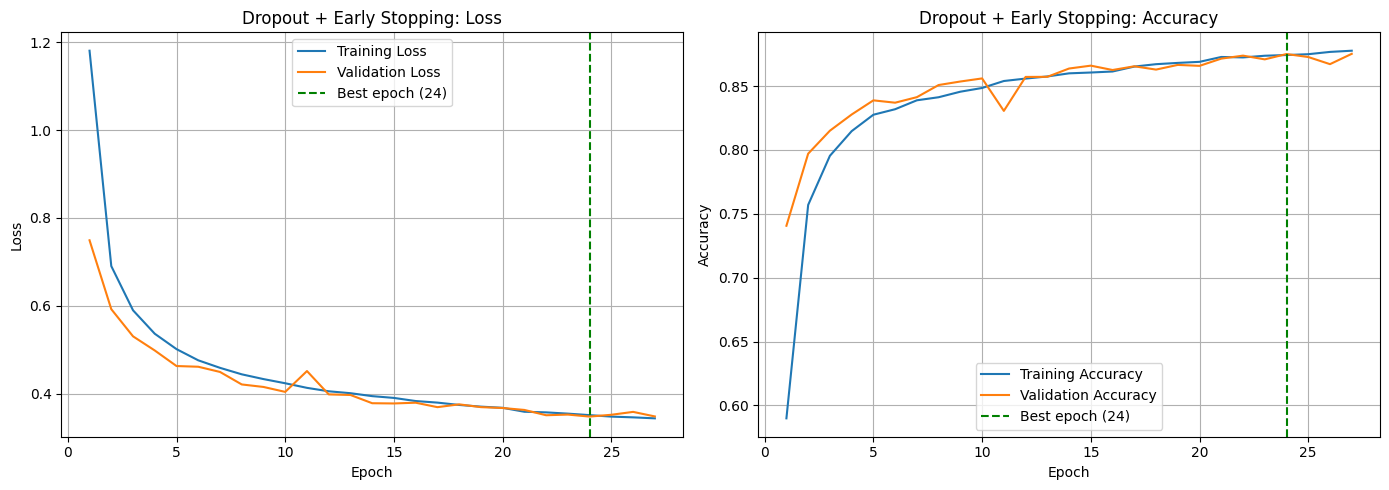

In [30]:
# Plot the combined model's learning curves.
combo_epochs = range(1, len(combo_loss_hist) + 1)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(combo_epochs, combo_loss_hist, label="Training Loss")
plt.plot(combo_epochs, combo_val_loss_hist, label="Validation Loss")
plt.axvline(combo_best_epoch, color="green", linestyle="--",
            label=f"Best epoch ({combo_best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Dropout + Early Stopping: Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(combo_epochs, combo_acc_hist, label="Training Accuracy")
plt.plot(combo_epochs, combo_val_acc_hist, label="Validation Accuracy")
plt.axvline(combo_best_epoch, color="green", linestyle="--",
            label=f"Best epoch ({combo_best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Dropout + Early Stopping: Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

 ---
<center> 

# End of Class
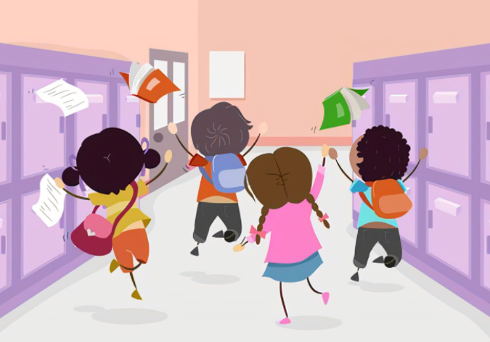
+++++++++++++++++





:)
---
</center>

